# Lab 1: Introduction to Deep Reinforcement Learning 🤖
### Reinforcement Learning and Generative AI
#### Master's Degree Programme in Applications of AI to Industry and Communications
#### University of Alcalá

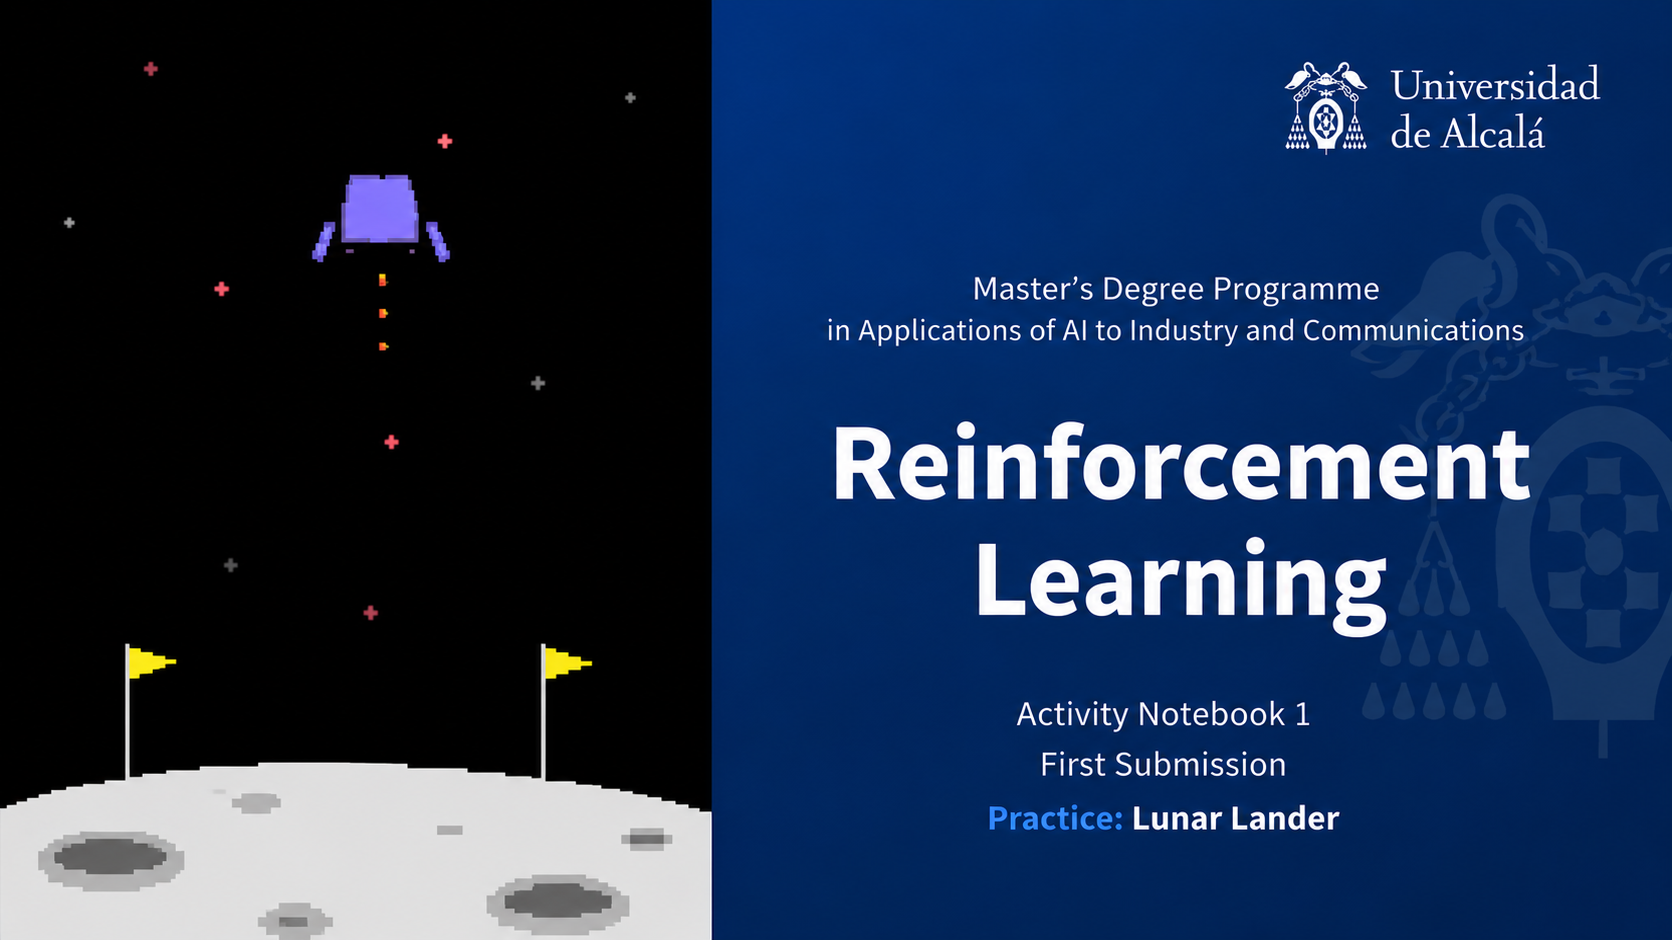

Welcome to your first lab assignment in the Reinforcement Learning module! In this comprehensive notebook, you will train your very first **Deep Reinforcement Learning (DRL) agent**. Specifically, we will be training a Lunar Lander agent to successfully navigate and land on the Moon 🌕 using **Stable-Baselines3**, an industry-standard DRL library.

This assignment is part of the **Master’s Degree Programme in Applications of AI to Industry and Communications**, offered by the University of Alcalá. The Master’s Degree provides advanced training in applied Artificial Intelligence, including machine learning, deep learning, generative AI, and foundation models/LLMs for industrial and technological environments. 

Throughout this notebook, you will find detailed theoretical explanations of the concepts at play, followed by interleaved questions designed to test your understanding. Please answer the questions in the provided text cells.

⬇️ Here is an example of what **you will achieve in just a couple of minutes.** ⬇️

> [!TIP]
> **💡 Originality & Research Bonus:**
> In this assignment, originality, scientific curiosity, and independent research are actively rewarded! Students who explore different neural network architectures (e.g., custom MLP hidden layer dimensions), experiment with hyperparameter tuning (learning rate, discount factor $\gamma$, GAE $\lambda$, clipping range), compare policy behaviors, or thoroughly document their findings will receive extra credit. Don't hesitate to propose innovative solutions!


In [ ]:
%%html
<video controls autoplay><source src="https://huggingface.co/sb3/ppo-LunarLander-v2/resolve/main/replay.mp4" type="video/mp4"></video>

## 1. Fundamentals of Reinforcement Learning 📚

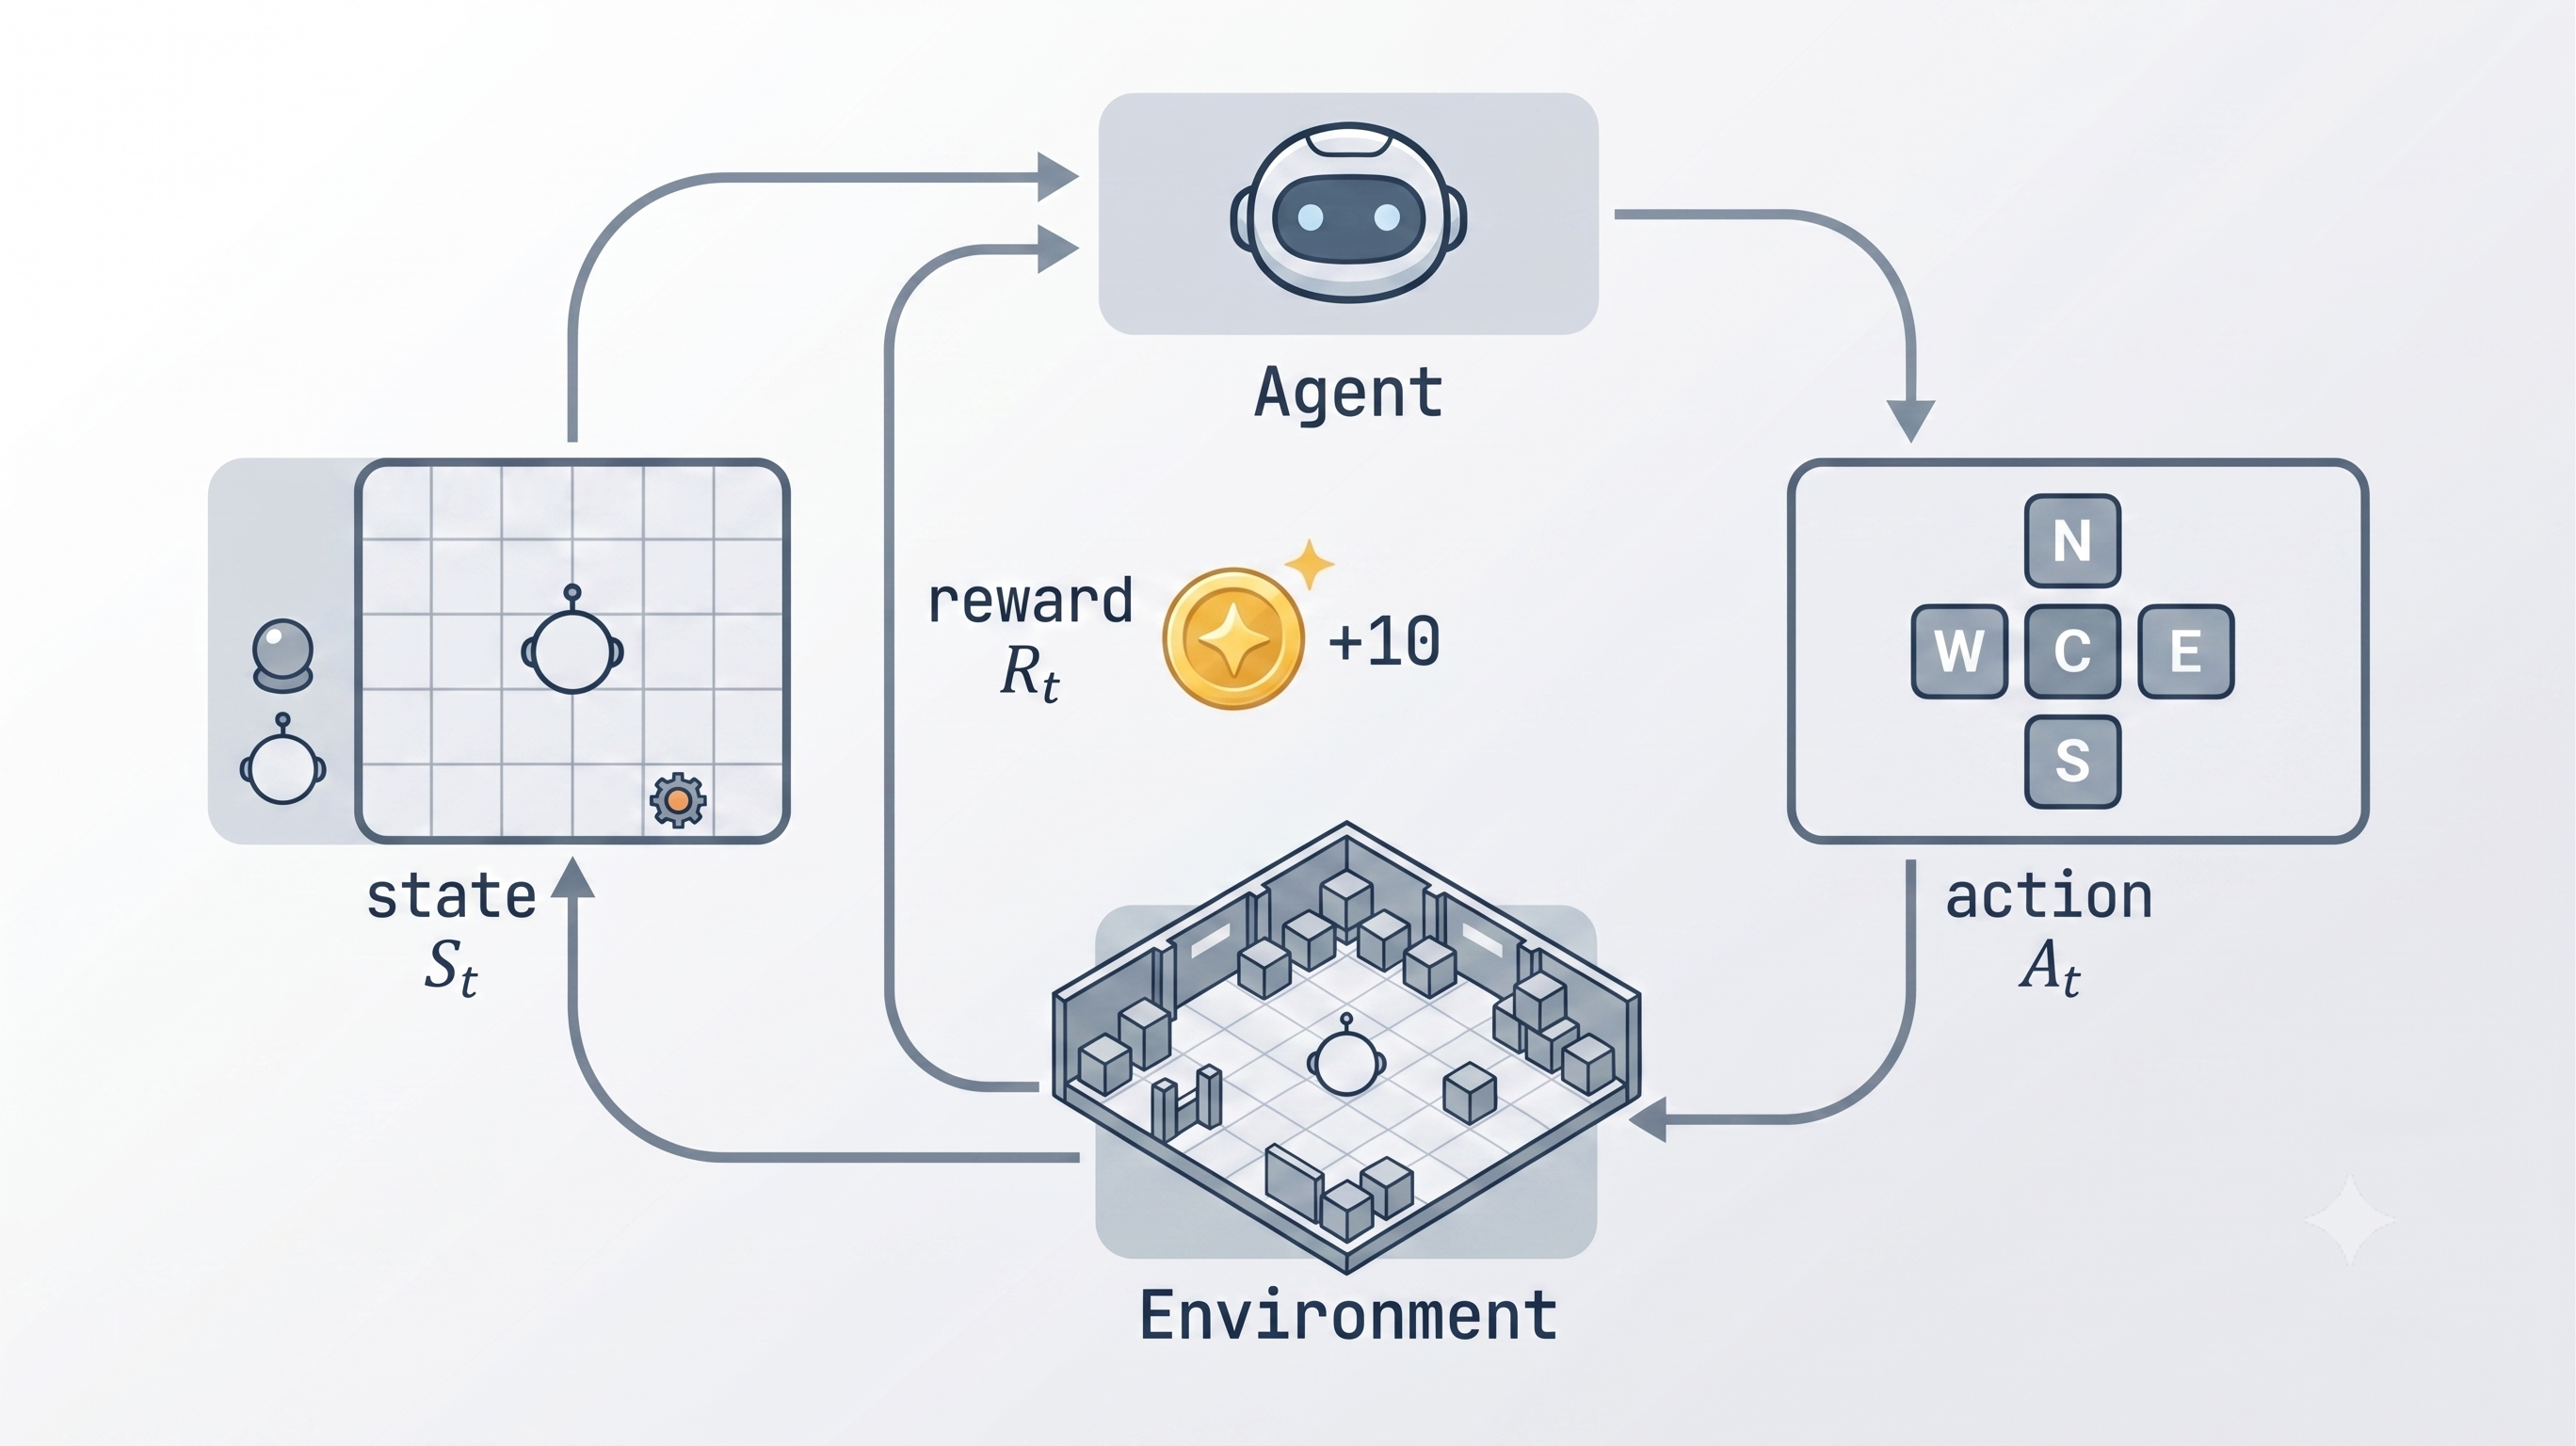

Before we dive into the code, let's establish a solid foundation of the theoretical concepts governing Reinforcement Learning.

Reinforcement Learning is a computational approach to understanding and automating goal-directed learning and decision making. Unlike supervised learning, where the model is provided with labeled correct actions, an RL agent must discover which actions yield the most reward by **interacting with its environment through trial and error**.

### The Markov Decision Process (MDP)
The interaction between the agent and the environment is typically formulated as a Markov Decision Process (MDP). At each discrete time step $t$, the agent receives a representation of the environment's **State ($S_t$)** or **Observation ($O_t$)**, and based on this, selects an **Action ($A_t$)**. 

One time step later, as a consequence of its action, the agent receives a scalar **Reward ($R_{t+1}$)**, and finds itself in a new state, $S_{t+1}$. The sequence of these interactions forms an episode: $S_0, A_0, R_1, S_1, A_1, R_2, ...$

### The Reward Hypothesis
The central premise of RL is the **Reward Hypothesis**: *"All of what we mean by goals and purposes can be well thought of as the maximization of the expected value of the cumulative sum of a received scalar signal (called reward)."* Therefore, the agent's sole objective is to maximize the expected total reward over the long run, commonly referred to as the **Expected Return**.

---
### 📝 Question 1: State vs. Observation
In academic literature, a distinction is often made between the true *State* of the environment and the *Observation* provided to the agent (leading to Partially Observable MDPs or POMDPs). 
**In the context of a real-world robotic Lunar Lander, describe the difference between the full true state of the physical environment and the observation vector provided to the agent. Why is this distinction important?**


*Your answer here...*


## 2. Setting up the Computational Environment 🖥️

To accelerate the agent's training, we will utilize GPU acceleration. Please ensure your environment (e.g., Colab or local Jupyter) is configured to use a GPU (`Runtime > Change Runtime type > Hardware Accelerator > GPU` (The free GPU is suitable for this course)).

The following cells will install the necessary dependencies:
- `gymnasium[box2d]`: The physics engine and environment interface containing the LunarLander-v3 environment.
- `stable-baselines3[extra]`: The deep reinforcement learning library containing our algorithm implementations.
- `huggingface_sb3`: Utility code for model sharing.


In [ ]:
import sys
import os

# Install system dependencies only in Google Colab or Debian/Ubuntu Linux with apt
# (Windows and macOS do not use apt-get and have native display/graphics support)
if "google.colab" in sys.modules or (sys.platform.startswith("linux") and os.path.exists("/usr/bin/apt-get")):
    !apt-get update -qq
    !apt-get install -y -qq swig cmake ffmpeg xvfb python3-opengl
else:
    print(f"ℹ️ Running on {sys.platform}: skipping apt-get (native system graphics will be used).")


In [ ]:
# 1. Install swig first to build Box2D C++ bindings
!pip install -q swig

# 2. Install Gymnasium with Box2D physics engine
!pip install -q "gymnasium[box2d]>=0.28.1"

# 3. Install Stable-Baselines3, virtual display, and Hugging Face integration
# Note: --no-deps prevents downgrading modern huggingface-hub required by Colab/transformers
!pip install -q "stable-baselines3[extra]>=2.0.0" pyvirtualdisplay wasabi
!pip install -q --no-deps huggingface_sb3


In [ ]:
import sys

# Virtual display for headless environments (e.g. Google Colab / headless Linux)
# On Windows and macOS, native display systems are used automatically; Xvfb is neither needed nor supported.
if sys.platform.startswith("linux"):
    try:
        from pyvirtualdisplay import Display
        virtual_display = Display(visible=0, size=(1400, 900))
        virtual_display.start()
        print("🖥️ Virtual display started (headless Linux / Colab).")
    except Exception as e:
        print(f"ℹ️ Virtual display skipped ({e}). Native graphical display will be used.")
else:
    print(f"ℹ️ Running on {sys.platform}: virtual display (Xvfb) skipped, using native graphical display.")


In [ ]:
import random
import numpy as np
import torch
import gymnasium as gym

from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.monitor import Monitor

# Set random seed for full reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


## 3. Warm-up: A Quick Taste of Reinforcement Learning with CartPole-v1 🕹️

Before diving into the lunar landing mission, let's build an intuitive understanding of the core **Reinforcement Learning Loop** with the classic **CartPole-v1** benchmark.

In **CartPole-v1**, a pole is attached by an un-actuated joint to a cart moving along a frictionless track. The goal is to keep the pole balanced upright by applying horizontal forces to the cart:

- **State / Observation Space ($S_t$):** A continuous 4-element vector:
  1. `state[0]`: Cart Position ($x \in [-4.8, 4.8]$)
  2. `state[1]`: Cart Velocity ($\dot{x}$)
  3. `state[2]`: Pole Angle ($\theta \in [-24^\circ, 24^\circ]$)
  4. `state[3]`: Pole Angular Velocity ($\dot{\theta}$)
- **Action Space ($A_t$):** Discrete with 2 possible decisions:
  - `0`: Push cart to the **Left ⬅️**
  - `1`: Push cart to the **Right ➡️**
- **Reward ($R_{t+1}$):** A scalar feedback of **$+1.0$** for every single time step that the pole remains upright (angle $\le \pm 12^\circ$ and cart position $|x| \le 2.4$).

Let's interact directly with the environment by executing the step loop below!

In [ ]:
# ------------------------------------------------------------------
# TASK 0: Complete the Agent-Environment Loop for CartPole-v1
# ------------------------------------------------------------------
import gymnasium as gym

# 1. Create our CartPole environment
env_cartpole = gym.make("CartPole-v1")

# 2. Reset the environment with our fixed SEED to get the initial state
# TODO: Reset the environment
state, info = env_cartpole.reset(seed=SEED)

print("Initial State [Cart Pos, Cart Vel, Pole Angle, Pole Vel]:", state.round(4))
print("-" * 65)

total_reward = 0
for step in range(30):
    # TODO: Choose an action. Try sampling random actions from the action space:
    # action = env_cartpole.action_space.sample()
    # Or try a simple heuristic rule: action = 1 if state[2] > 0 else 0
    action = env_cartpole.action_space.sample()
    
    # TODO: Execute the chosen action in the environment
    # Receive: (next_state, reward, terminated, truncated, info)
    state, reward, terminated, truncated, info = env_cartpole.step(action)
    total_reward += reward
    
    direction = "RIGHT ➡️" if action == 1 else "LEFT ⬅️"
    print(f"Step {step+1:02d} | Action: {action} ({direction}) | Reward: +{reward:.0f} | State: {state.round(3)}")
    
    if terminated or truncated:
        print(f"\n⚠️ Episode finished after {step+1} steps! Total Reward: {total_reward}")
        break

env_cartpole.close()

---
### 📝 Question 0: Anatomy of the Reinforcement Learning Loop
Based on your hands-on execution of the CartPole-v1 loop:
1. **State & Action Dynamics:** What physical quantity does `state[2]` represent, and how does taking action `0` vs `1` influence the cart and the pole?
2. **The Reward Hypothesis:** Why is receiving a simple $+1$ per timestep sufficient to teach an agent to balance the pole for as long as possible?


*Your answer here...*


### 🎥 Visualizing Learning Progression in CartPole-v1: Beginning, Middle & Final

To clearly observe how an agent learns from trial and error before tackling our lunar lander, let's train a lightweight **PPO** agent on **CartPole-v1** and record its policy across three key learning phases:
1. **Beginning (0 steps / Untrained):** Random actions with no knowledge of dynamics. The pole tilts and crashes immediately (< 20 steps). The video holds the final failure state for 2.5 seconds so you can examine the exact moment of failure.
2. **Middle (~3,000 steps / Partially Trained):** Begins developing counter-balancing instincts, sustaining equilibrium for 60–100 steps before tilting over. The failure frame is held for 2.5 seconds.
3. **Final (20,000 steps / Converged):** Fully stabilized closed-loop control maintaining the pole upright for the full 500-step time limit.


In [ ]:
import imageio
import base64
import numpy as np
from PIL import Image, ImageDraw
from IPython.display import HTML
import warnings
from stable_baselines3 import PPO

# Helper to draw an informative status banner on the final frame
def add_status_banner(frame, text, bg_color=(200, 30, 30), text_color=(255, 255, 255)):
    img = Image.fromarray(frame).convert("RGBA")
    w, h = img.size
    overlay = Image.new("RGBA", img.size, (0, 0, 0, 0))
    draw = ImageDraw.Draw(overlay)
    banner_h = 32
    draw.rectangle([(0, h - banner_h), (w, h)], fill=(*bg_color, 215))
    draw.text((12, h - banner_h + 8), text, fill=text_color)
    combined = Image.alpha_composite(img, overlay)
    return np.array(combined.convert("RGB"))

# Helper to record an episode video across learning checkpoints with failure-frame hold
def record_cartpole_video(model_eval, filename, seed=SEED, max_steps=500, fps=20, hold_seconds=0.8):
    eval_env = gym.make("CartPole-v1", render_mode="rgb_array")
    obs, info = eval_env.reset(seed=seed)
    frames = [eval_env.render()]
    total_reward = 0
    step_count = 0
    terminated = truncated = False

    for step in range(max_steps):
        step_count = step + 1
        if model_eval is None:
            action = eval_env.action_space.sample()
        else:
            action, _states = model_eval.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = eval_env.step(action)
        total_reward += reward
        frames.append(eval_env.render())
        if terminated or truncated:
            break

    is_success = (total_reward >= 475)

    # If terminated due to pole falling, continue physics so the pole visibly drops completely flat
    if terminated and not is_success:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fall_action = 0 if obs[2] > 0 else 1
            for _ in range(25):
                obs, _, _, _, _ = eval_env.step(fall_action)
                frames.append(eval_env.render())
                if abs(obs[2]) > 1.55:  # Pole horizontal on the ground (> 90 deg)
                    break

    eval_env.close()

    status_text = f"✅ STABILIZED ({int(total_reward)} steps)" if is_success else f"💥 POLE FELL (Failed at step {step_count})"
    banner_bg = (34, 139, 34) if is_success else (178, 34, 34)

    # Brief hold on fallen / final frame (0.8s) so outcome is clearly seen without slowing playback
    if frames:
        terminal_frame = add_status_banner(frames[-1], status_text, bg_color=banner_bg)
        frames[-1] = terminal_frame
        hold_frames = max(1, int(fps * hold_seconds))
        for _ in range(hold_frames):
            frames.append(terminal_frame)

    imageio.mimsave(filename, frames, fps=fps)
    print(f"🎬 Saved {filename} | Total Steps: {int(total_reward)} | Duration: {len(frames)/fps:.1f}s ({status_text})")
    return int(total_reward)

# 1. Beginning Phase: Untrained agent with random actions
print("--- 1. Recording Untrained CartPole (0 steps) ---")
steps_untrained = record_cartpole_video(None, "cartpole_untrained.mp4", seed=SEED)

# 2. Middle Phase: Partially trained agent (~3,000 steps)
print("\n--- 2. Training to Mid-Checkpoint (3,000 steps) ---")
env_cp = gym.make("CartPole-v1")
model_cp = PPO("MlpPolicy", env_cp, device="cpu", verbose=0, seed=SEED)
model_cp.learn(total_timesteps=3000)
steps_mid = record_cartpole_video(model_cp, "cartpole_mid.mp4", seed=SEED)

# 3. Final Phase: Converged policy (total 20,000 steps)
print("\n--- 3. Training to Final Convergence (remaining 17,000 steps) ---")
model_cp.learn(total_timesteps=17000, reset_num_timesteps=False)
steps_final = record_cartpole_video(model_cp, "cartpole_final.mp4", seed=SEED)
env_cp.close()

# Load and encode videos in base64 for smooth HTML5 side-by-side rendering
b64_untrained = base64.b64encode(open("cartpole_untrained.mp4", "rb").read()).decode("utf-8")
b64_mid = base64.b64encode(open("cartpole_mid.mp4", "rb").read()).decode("utf-8")
b64_final = base64.b64encode(open("cartpole_final.mp4", "rb").read()).decode("utf-8")

HTML(f"""
<div style="font-family: Arial, sans-serif; text-align: center; margin: 15px 0;">
  <h3 style="color: #1a1a1a;">🕹️ CartPole-v1 Learning Progression Across Training Phases</h3>
  <div style="display: flex; justify-content: space-around; flex-wrap: wrap; gap: 15px; margin-top: 15px;">
    
    <!-- 1. Untrained -->
    <div style="flex: 1; min-width: 260px; background: #fff1f0; border: 1px solid #ffa39e; border-radius: 8px; padding: 12px;">
      <h4 style="color: #cf1322; margin-top: 0;">1. Beginning (0 steps) 💥</h4>
      <video width="100%" height="220" controls autoplay loop muted style="border-radius: 6px; box-shadow: 0 2px 4px rgba(0,0,0,0.1);">
        <source src="data:video/mp4;base64,{b64_untrained}" type="video/mp4">
      </video>
      <p style="font-size: 13px; color: #555; margin-top: 8px;"><b>Untrained ({steps_untrained} steps):</b> Rapid tilt and fall. Pole tumbles to the ground and holds 0.8s.</p>
    </div>

    <!-- 2. Mid -->
    <div style="flex: 1; min-width: 260px; background: #fffbe6; border: 1px solid #ffe58f; border-radius: 8px; padding: 12px;">
      <h4 style="color: #d48806; margin-top: 0;">2. Middle (~3k steps) 🟡</h4>
      <video width="100%" height="220" controls autoplay loop muted style="border-radius: 6px; box-shadow: 0 2px 4px rgba(0,0,0,0.1);">
        <source src="data:video/mp4;base64,{b64_mid}" type="video/mp4">
      </video>
      <p style="font-size: 13px; color: #555; margin-top: 8px;"><b>Partially Trained ({steps_mid} steps):</b> Counteracts tilt for ~60–100 steps before tipping. Pole falls to ground and holds 0.8s.</p>
    </div>

    <!-- 3. Final -->
    <div style="flex: 1; min-width: 260px; background: #f6ffed; border: 1px solid #b7eb8f; border-radius: 8px; padding: 12px;">
      <h4 style="color: #389e0d; margin-top: 0;">3. Final (20k steps) 🏆</h4>
      <video width="100%" height="220" controls autoplay loop muted style="border-radius: 6px; box-shadow: 0 2px 4px rgba(0,0,0,0.1);">
        <source src="data:video/mp4;base64,{b64_final}" type="video/mp4">
      </video>
      <p style="font-size: 13px; color: #555; margin-top: 8px;"><b>Fully Converged ({steps_final} steps):</b> Smooth continuous balance reaching max limit (500 steps).</p>
    </div>

  </div>
</div>
""")


## 4. Understanding Gymnasium and the LunarLander-v3 Environment 🌛

Gymnasium (formerly Gym, maintained by the Farama Foundation) is the standard API for reinforcement learning, providing a unified interface for defining and interacting with environments.

The core interaction loop in Gymnasium consists of two primary methods:
1. `env.reset()`: Initializes or restarts the environment, returning the initial observation ($O_0$).
2. `env.step(action)`: Applies the chosen action to the environment. It returns a tuple containing:
   - `observation`: The new state of the environment ($O_{t+1}$).
   - `reward`: The scalar feedback obtained from taking the action ($R_{t+1}$).
   - `terminated`: A boolean indicating if the episode has reached a terminal state (e.g., the lander crashed or landed successfully).
   - `truncated`: A boolean indicating if the episode was prematurely halted (e.g., reaching a time limit).
   - `info`: A dictionary containing auxiliary diagnostic information.

Read and execute the following loop to see this in practice:


In [ ]:
import gymnasium as gym

# First, we create our environment called LunarLander-v3
env = gym.make("LunarLander-v3")

# Then we reset this environment with our fixed seed
observation, info = env.reset(seed=SEED)

for _ in range(20):
  # Take a random action
  action = env.action_space.sample()
  print("Action taken:", action)

  # Do this action in the environment and get
  # next_state, reward, terminated, truncated and info
  observation, reward, terminated, truncated, info = env.step(action)

  # If the game is terminated (in our case we land, crashed) or truncated (timeout)
  if terminated or truncated:
      # Reset the environment
      print("Environment is reset")
      observation, info = env.reset(seed=SEED)

env.close()

### Deep Dive: The LunarLander-v3 Environment 🌛

To successfully solve the Lunar Lander problem, we must understand the Observation Space, the Action Space, and the Reward Function. Let's inspect them.


In [ ]:
# We create our environment with gym.make("<name_of_the_environment>")
env = gym.make("LunarLander-v3")
env.reset(seed=SEED)
print("_____OBSERVATION SPACE_____ \n")
print("Observation Space Shape", env.observation_space.shape)
print("Sample observation", env.observation_space.sample()) # Get a random observation


**Observation Space**
The observation is an 8-dimensional continuous vector:
1. Horizontal coordinate ($x$)
2. Vertical coordinate ($y$)
3. Horizontal velocity ($\dot{x}$)
4. Vertical velocity ($\dot{y}$)
5. Angle ($\theta$)
6. Angular velocity ($\dot{\theta}$)
7. Left leg contact (boolean)
8. Right leg contact (boolean)


In [ ]:
print("\n _____ACTION SPACE_____ \n")
print("Action Space Shape", env.action_space.n)
print("Action Space Sample", env.action_space.sample()) # Take a random action

**Action Space**
The action space is discrete, offering 4 distinct choices at each timestep:
- 0: Do nothing
- 1: Fire left orientation engine
- 2: Fire main engine
- 3: Fire right orientation engine

**Reward Function**
Reward shaping is critical. The environment provides positive rewards for moving closer to the landing pad and making safe contact. Conversely, it provides negative rewards (penalties) for moving away, firing engines (which consumes fuel), and crashing.

---
### 📝 Question 2: Analyzing the Reward Function
The reward function explicitly penalizes the agent for firing its engines (e.g., -0.3 points per frame for the main engine). 
**If we completely removed the fuel consumption penalties from the reward function, how might the agent's resulting optimal behavior change? Would it still learn to land safely? Explain your reasoning.**


*Your answer here...*


In [ ]:
# Create the environment with fixed seed for reproducibility
env = make_vec_env('LunarLander-v3', n_envs=16, seed=SEED)

## 5. The Algorithm: Proximal Policy Optimization (PPO) 🧠

To solve this problem, we will utilize **Proximal Policy Optimization (PPO)**, implemented in the Stable-Baselines3 library. PPO is widely considered an industry-standard, state-of-the-art algorithm due to its robust performance and relative ease of tuning.

### Policy-Based vs. Value-Based Methods
In Deep RL, we use Neural Networks as function approximators. There are two primary paradigms:
- **Value-Based Methods (e.g., DQN):** The neural network learns to estimate the expected return (Q-value) for taking a specific action in a specific state. The policy is implicitly defined by greedily choosing the action with the highest estimated value.
- **Policy-Based Methods (e.g., REINFORCE):** The neural network directly outputs a probability distribution over the available actions given a state. The network parameters are updated to increase the probability of actions that lead to high rewards.

### The Actor-Critic Architecture
PPO utilizes an **Actor-Critic** architecture, combining the strengths of both paradigms:
- **The Actor (Policy):** Decides *which action to take*. It outputs the action probability distribution.
- **The Critic (Value Function):** Evaluates *how good the current state is*. It estimates the expected return from the current state, providing a baseline to judge the Actor's choices, thereby reducing the variance of the learning updates.

PPO specifically improves upon earlier methods by introducing a *clipping* mechanism in its objective function, preventing catastrophically large updates to the policy network. This ensures monotonic improvement and stable training.



> 📖 **Official Documentation:** This lab uses the **Stable-Baselines3** library.
> Full reference, API docs, and examples are available at:
> **[https://stable-baselines3.readthedocs.io/en/master/](https://stable-baselines3.readthedocs.io/en/master/)**
> In particular, see the [PPO documentation](https://stable-baselines3.readthedocs.io/en/master/modules/ppo.html) for all available hyperparameters.

---
### 📝 Question 3: Actor-Critic Dynamics
Proximal Policy Optimization (PPO) relies heavily on the Actor-Critic interplay.
**Briefly explain why using a Critic to mathematically evaluate states is advantageous for training the Actor, compared to relying solely on the raw, sparse cumulative rewards obtained at the end of an episode.**


*Your answer here...*


In [ ]:
# TODO: Define a PPO MlpPolicy architecture
# We use MultiLayerPerceptron (MLPPolicy) because the input is a vector,
# if we had frames as input we would use CnnPolicy
model =

## 6. Agent Training and Hyperparameters 🏃

We are now ready to instantiate our PPO model and begin the training loop. We will use an `MlpPolicy` (Multi-Layer Perceptron), which is appropriate since our observation space is a 1D vector. If we were processing raw pixel frames, a `CnnPolicy` (Convolutional Neural Network) would be required.

### The Discount Factor ($\gamma$)
Among the hyperparameters, the discount factor `gamma` ($\gamma$) is crucial. It determines the present value of future rewards. A reward $R$ received $k$ steps in the future is worth $\gamma^{k-1} R$ today. This models the concept that immediate rewards are often more certain and valuable than distant, uncertain ones.

Let's train the agent for 1,000,000 timesteps. This process may take 15-20 minutes on a standard GPU.

---
### 📝 Question 4: Hyperparameter Influence
In the code above, the discount factor `gamma` is set to `0.999`. 
**What does a $\gamma$ value extremely close to 1 imply about the agent's foresight and strategic planning? If we incorrectly configured the system and set $\gamma = 0.1$, how would the agent's behavior change during the lunar descent?**


*Your answer here...*


In [ ]:
# TODO: Train it for 1,000,000 timesteps

# TODO: Specify file name for model and save the model to file
model_name = "ppo-LunarLander-v3"


## 7. Model Evaluation and Determinism 📈

Once the training process concludes, we must evaluate the robustness and competency of our learned policy. We do this by instantiating a separate, clean evaluation environment and recording the agent's cumulative reward across multiple episodes.

### Exploration vs. Exploitation
During training, the Actor network outputs a *probability distribution*. The agent samples from this distribution, allowing it to *explore* new actions and discover better strategies (stochastic behavior).
However, during evaluation, we want the agent to perform optimally by exploiting the knowledge it has gained. Therefore, we set `deterministic=True`, forcing the agent to always select the single action with the highest probability.

---
### 📝 Question 5: Evaluation Strategy
During the evaluation phase using `evaluate_policy` below, we explicitly set `deterministic=True`.
**Explain why it is critical to disable exploratory, stochastic behavior when officially evaluating the final performance metric of the trained policy. What risks do we face if we evaluate stochastically?**


*Your answer here...*


In [ ]:
# TODO: Evaluate the agent
# Create a new environment for evaluation
eval_env =

# Evaluate the model with 10 evaluation episodes and deterministic=True
mean_reward, std_reward =

# Print the results



## 8. Assignment Delivery 🚀

As part of your Master's assignment delivery, you must publish your trained model to the **Hugging Face Hub** 🤗. This process evaluates your model, generates a replay video, constructs a model card, and uploads the artifacts.

To successfully pass this lab assignment, your agent must achieve a stable mean reward of **>= 200 points**.

---

### Step 1️⃣ — Create a Hugging Face Account and Generate a Write Token

> 🔑 **What is a Hugging Face token?**
> Hugging Face is a platform (like GitHub, but for AI models) that hosts trained model files. A **write token** authenticates your account and allows the notebook to upload your model to the Hub automatically.

**To get your token:**
1. Go to [https://huggingface.co](https://huggingface.co) and create a free account (or log in if you already have one).
2. Once logged in, click on your profile picture (top-right) → **Settings** → **Access Tokens** in the left sidebar.
   - Direct link: [https://huggingface.co/settings/tokens](https://huggingface.co/settings/tokens)
3. Click **"New token"**, choose a name (e.g., `rl-lab-token`), set the **Role** to **`Write`**, and click **"Generate a token"**.
4. **Copy the token** — it starts with `hf_...`. Store it securely (you will not be able to see it again after closing the page).

> ⚠️ **Important:** Keep your token private! Never share it or paste it in a public notebook or message. It grants write access to your Hugging Face account.

Run the cell below to authenticate:


In [ ]:
from huggingface_hub import notebook_login
notebook_login()
!git config --global credential.helper store

2️⃣ We're now ready to push our trained agent to the Hub using the `package_to_hub()` function.


In [ ]:
import gymnasium as gym
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.monitor import Monitor

try:
    from huggingface_sb3 import package_to_hub
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "huggingface_sb3"])
    from huggingface_sb3 import package_to_hub

# TODO: Define the name of the environment (use "LunarLander-v3" on Gymnasium >= 1.0.0, or "LunarLander-v2" on older versions)
env_id = "LunarLander-v3"

## TODO: Define a repo_id
## repo_id is the id of the model repository from the Hugging Face Hub (repo_id = {organization}/{repo_name} for instance {username}/ppo-LunarLander-v3)
repo_id = 

# Create the evaluation env and set the render_mode="rgb_array"
eval_env = DummyVecEnv([lambda: Monitor(gym.make(env_id, render_mode="rgb_array"))])

# TODO: Define the model architecture we used
model_architecture = ""

## TODO: Define the commit message
commit_message = ""

# method save, evaluate, generate a model card and record a replay video of your agent before pushing the repo to the hub
package_to_hub(model=model, # Our trained model
               model_name=model_name, # The name of our trained model
               model_architecture=model_architecture, # The model architecture we used: in our case PPO
               env_id=env_id, # Name of the environment
               eval_env=eval_env, # Evaluation Environment
               repo_id=repo_id, # id of the model repository from the Hugging Face Hub
               commit_message=commit_message)



## 9. Visualizing the Learning Progression: Beginning, Middle & Final 🎥

Let's compare your agent's behavior across the three key phases of reinforcement learning in **LunarLander-v3**:
1. **Beginning (0 steps / Untrained):** Random thruster firing, tumbling, and rapid crash into the lunar surface. The video holds the crash frame for 2.5 seconds so you can clearly see the impact and damage.
2. **Middle (~30k steps / Partially Trained):** Agent learns to orient thrusters downwards and descend towards the pad, but comes in with excessive velocity or tilts, bouncing or crashing on landing. Holds the failure frame for 2.5s.
3. **Final (Trained):** Fully converged policy mastering soft pinpoint touchdown between the landing flags with engines cut.


In [ ]:
def make_lunar_env(**kwargs):
    try:
        return gym.make("LunarLander-v3", **kwargs)
    except Exception:
        return gym.make("LunarLander-v2", **kwargs)

import imageio
import base64
import numpy as np
from PIL import Image, ImageDraw
from IPython.display import HTML
import warnings
from stable_baselines3 import PPO

def add_lunar_banner(frame, text, bg_color=(200, 30, 30), text_color=(255, 255, 255)):
    img = Image.fromarray(frame).convert("RGBA")
    w, h = img.size
    overlay = Image.new("RGBA", img.size, (0, 0, 0, 0))
    draw = ImageDraw.Draw(overlay)
    banner_h = 34
    draw.rectangle([(0, h - banner_h), (w, h)], fill=(*bg_color, 215))
    draw.text((12, h - banner_h + 9), text, fill=text_color)
    combined = Image.alpha_composite(img, overlay)
    return np.array(combined.convert("RGB"))

def record_lunar_progression_video(model_eval, filename, seed=SEED, max_steps=500, fps=24, hold_seconds=0.8):
    eval_env = make_lunar_env(render_mode="rgb_array")
    obs, info = eval_env.reset(seed=seed)
    frames = [eval_env.render()]
    total_reward = 0
    step_count = 0
    terminated = truncated = False

    for step in range(max_steps):
        step_count = step + 1
        if model_eval is None:
            action = eval_env.action_space.sample()
        else:
            action, _states = model_eval.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = eval_env.step(action)
        total_reward += reward
        frames.append(eval_env.render())
        if terminated or truncated:
            break

    # If terminated on crash/landing, capture brief physics settle
    if terminated:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            for _ in range(8):
                try:
                    eval_env.step(0)
                    frames.append(eval_env.render())
                except Exception:
                    break
    eval_env.close()

    is_success = (total_reward >= 150)
    is_crash = (terminated and total_reward < 50)
    if is_success:
        status_text = f"🌕 TOUCHDOWN! (Score: {total_reward:+.1f} | {step_count} steps)"
        banner_bg = (34, 139, 34)
    elif is_crash:
        status_text = f"💥 CRASH ON SURFACE (Score: {total_reward:+.1f} | Step {step_count})"
        banner_bg = (178, 34, 34)
    else:
        status_text = f"⏳ TIMEOUT / DRIFT (Score: {total_reward:+.1f} | Step {step_count})"
        banner_bg = (204, 102, 0)

    # Brief hold on outcome frame (0.8s)
    if frames:
        terminal_frame = add_lunar_banner(frames[-1], status_text, bg_color=banner_bg)
        frames[-1] = terminal_frame
        hold_frames = max(1, int(fps * hold_seconds))
        for _ in range(hold_frames):
            frames.append(terminal_frame)

    imageio.mimsave(filename, frames, fps=fps)
    print(f"🎬 Saved {filename} | Reward: {total_reward:+.1f} | {status_text} | Duration: {len(frames)/fps:.1f}s")
    return total_reward, step_count

# 1. Beginning Phase: Untrained agent with random actions (0 steps)
print("--- 1. Recording Untrained LunarLander (0 steps) ---")
rew_untrained, steps_untrained = record_lunar_progression_video(None, "lunar_lander_untrained.mp4", seed=SEED)

# 2. Middle Phase: Partially trained agent (~30,000 steps checkpoint)
print("\n--- 2. Training Mid-Checkpoint Policy (30,000 steps) ---")
env_mid = make_lunar_env()
model_mid = PPO("MlpPolicy", env_mid, n_steps=1024, verbose=0, seed=SEED)
model_mid.learn(total_timesteps=30000)
rew_mid, steps_mid = record_lunar_progression_video(model_mid, "lunar_lander_mid.mp4", seed=SEED)
env_mid.close()

# 3. Final Phase: Fully converged agent (from Section 6)
print("\n--- 3. Recording Final Converged Policy ---")
rew_final, steps_final = record_lunar_progression_video(model, "lunar_lander_final.mp4", seed=SEED)

b64_lunar_untrained = base64.b64encode(open("lunar_lander_untrained.mp4", "rb").read()).decode("utf-8")
b64_lunar_mid = base64.b64encode(open("lunar_lander_mid.mp4", "rb").read()).decode("utf-8")
b64_lunar_final = base64.b64encode(open("lunar_lander_final.mp4", "rb").read()).decode("utf-8")

HTML(f"""
<div style="font-family: Arial, sans-serif; text-align: center; margin: 15px 0;">
  <h3 style="color: #1a1a1a;">🚀 LunarLander-v3 Learning Progression Across Training Phases</h3>
  <div style="display: flex; justify-content: space-around; flex-wrap: wrap; gap: 15px; margin-top: 15px;">
    
    <!-- 1. Untrained -->
    <div style="flex: 1; min-width: 260px; background: #fff1f0; border: 1px solid #ffa39e; border-radius: 8px; padding: 12px;">
      <h4 style="color: #cf1322; margin-top: 0;">1. Beginning (0 steps) 💥</h4>
      <video width="100%" height="220" controls autoplay loop muted style="border-radius: 6px; box-shadow: 0 2px 4px rgba(0,0,0,0.1);">
        <source src="data:video/mp4;base64,{b64_lunar_untrained}" type="video/mp4">
      </video>
      <p style="font-size: 13px; color: #555; margin-top: 8px;"><b>Untrained ({rew_untrained:+.1f} pts):</b> Tumbling and crash. Brief 0.8s hold on impact.</p>
    </div>

    <!-- 2. Mid -->
    <div style="flex: 1; min-width: 260px; background: #fffbe6; border: 1px solid #ffe58f; border-radius: 8px; padding: 12px;">
      <h4 style="color: #d48806; margin-top: 0;">2. Middle (~30k steps) 🟡</h4>
      <video width="100%" height="220" controls autoplay loop muted style="border-radius: 6px; box-shadow: 0 2px 4px rgba(0,0,0,0.1);">
        <source src="data:video/mp4;base64,{b64_lunar_mid}" type="video/mp4">
      </video>
      <p style="font-size: 13px; color: #555; margin-top: 8px;"><b>Partially Trained ({rew_mid:+.1f} pts):</b> Fires thrusters, but bounces or tips over on landing. Brief 0.8s hold on touchdown.</p>
    </div>

    <!-- 3. Final -->
    <div style="flex: 1; min-width: 260px; background: #f6ffed; border: 1px solid #b7eb8f; border-radius: 8px; padding: 12px;">
      <h4 style="color: #389e0d; margin-top: 0;">3. Final (Trained) 🌕🏆</h4>
      <video width="100%" height="220" controls autoplay loop muted style="border-radius: 6px; box-shadow: 0 2px 4px rgba(0,0,0,0.1);">
        <source src="data:video/mp4;base64,{b64_lunar_final}" type="video/mp4">
      </video>
      <p style="font-size: 13px; color: #555; margin-top: 8px;"><b>Fully Trained ({rew_final:+.1f} pts):</b> Smooth descent, soft pinpoint landing between flags.</p>
    </div>

  </div>
</div>
""")


### 🎯 Tournament Scoring: Point Formula (LunarLander)

The score obtained by your agent is the cumulative reward per episode:

$$R_{\text{LunarLander}} = R_{\text{trajectory}} + 10 \cdot N_{\text{legs}} - 0.3 \cdot N_{\text{main}} - 0.03 \cdot N_{\text{side}} + R_{\text{terminal}}$$

- **$R_{\text{trajectory}}$ ($+100$ to $+140$ pts):** Points awarded for flying towards the landing pad while reducing speed and tilt.
- **$N_{\text{legs}}$ ($+10$ pts each):** Each leg making contact with the lunar surface.
- **$N_{\text{main}}$ ($-0.3$ pts/frame):** Fuel consumption of the main engine.
- **$N_{\text{side}}$ ($-0.03$ pts/frame):** Fuel consumption of side thrusters.
- **$R_{\text{terminal}}$:** **$+100$ pts** for safe touchdown inside the helipads, or **$-100$ pts** for a crash.



In [ ]:
%%writefile agent.py
import os
from stable_baselines3 import PPO

# Load the model
model_path = os.path.join(os.path.dirname(__file__), "ppo-LunarLander-v3.zip")
model = PPO.load(model_path)

def agent(observation):
    # Given an observation, predict the best action
    action, _states = model.predict(observation, deterministic=True)
    return int(action)


In [ ]:
!zip submission.zip ppo-LunarLander-v3.zip agent.py

### 🚀 Option A: Submit to the Class Tournament via Pull Request (Recommended)

You can automatically fork the repository, upload your model, and open a **Pull Request** to the class tournament leaderboard with a single click!

#### What happens when you run the cell below?

1. **🔀 Fork:** The script automatically creates a personal copy (*fork*) of `gramuah/RL_tournament` under your GitHub account — you only need to have a GitHub account and provide a token.
2. **📦 Upload:** Your `agent.py` and `ppo-LunarLander-v3.zip` files are uploaded to `submissions/lab1/<your_github_username>/` inside your fork.
3. **🔃 Pull Request:** A Pull Request (PR) is opened from your fork to the main repository. Think of it as formally proposing to add your agent to the tournament.
4. **🤖 Automatic CI Evaluation:** A GitHub Actions robot immediately runs your agent for **30 episodes** on fixed, fair seeds and posts a report card directly as a comment on your PR (within ~2 minutes). The report includes mean reward, success rate, and your tier (MASTERY / PASSED / NEEDS IMPROVEMENT).
5. **📊 Leaderboard Update:** Once an instructor reviews and merges your PR, your score appears on the [official tournament website](https://gramuah.github.io/RL_tournament/) and leaderboard.

> **Note:** If you submit again later (e.g., after improving your model), just re-run this cell. The script will update your existing fork branch and PR automatically. Your score on the leaderboard will be updated accordingly.

#### Prerequisite: GitHub Personal Access Token (PAT)

> 🔑 **What is a GitHub PAT?**
> It is a password substitute that the script uses to create the fork and upload files on your behalf, without ever seeing your actual GitHub password.

**To generate one:**
1. Go to [https://github.com/settings/tokens](https://github.com/settings/tokens) (log in to GitHub if needed).
2. Click **"Generate new token (classic)"**.
3. Give it a **name** (e.g., `rl-tournament-lab`), set **Expiration** to at least 30 days, and check the **`repo`** checkbox (full control of private repositories).
4. Click **"Generate token"** at the bottom of the page.
5. **Copy the token** immediately — it starts with `ghp_...`. You will not be able to see it again.
6. Paste it in the secure prompt below (it will not be displayed on screen).


In [ ]:
import getpass
import os
import urllib.request

# 1. Load the automated submission tool from the repository
_submit_candidates = [
    os.path.join("..", "..", "tournament", "submit.py"),
    os.path.join("tournament", "submit.py"),
]
_loaded = False
for _candidate in _submit_candidates:
    if os.path.exists(_candidate):
        with open(_candidate, "r", encoding="utf-8") as _f:
            exec(_f.read())
        _loaded = True
        break
if not _loaded:
    try:
        _code = urllib.request.urlopen("https://raw.githubusercontent.com/gramuah/RL_tournament/main/tournament/submit.py", timeout=30).read().decode("utf-8")
        if "_MAINTAINERS" not in _code:
            _code = urllib.request.urlopen("https://raw.githubusercontent.com/gramuah/RL_tournament/chore/rename-lab-notebooks/tournament/submit.py", timeout=30).read().decode("utf-8")
        exec(_code)
    except Exception:
        exec(urllib.request.urlopen("https://raw.githubusercontent.com/gramuah/RL_tournament/main/tournament/submit.py", timeout=30).read().decode("utf-8"))

# 2. Enter your GitHub Token securely
GITHUB_TOKEN = getpass.getpass("🔑 Enter your GitHub Personal Access Token: ")

# 3. Automatically fork, upload, and open the Pull Request!
pr_url = submit_lab(
    lab_id=1,
    files_to_submit={
        "agent.py": "agent.py",
        "ppo-LunarLander-v3.zip": "ppo-LunarLander-v3.zip"
    },
    github_token=GITHUB_TOKEN
)

### 🥊 Head-to-Head Agent Duel (Compare your agent against another student or a baseline)

Want to see **who lands faster in LunarLander-v3**, or how your agent handles exactly the same challenge as a classmate's agent?

You can compare your model and view the visualizations in the following ways:

1. **🌐 In the Interactive GitHub Pages Web Arena (One Click, No Code):**
   Visit the official public portal: **[https://gramuah.github.io/RL_tournament/](https://gramuah.github.io/RL_tournament/)**.
   Use the dropdown menus to select any classmate or baseline and watch the **synchronized split-screen video replay**, real-time telemetry, and speed rankings.

2. **⚙️ Run Duels on Demand in GitHub Actions:**
   In **[Actions > Run Agent Duel](https://github.com/gramuah/RL_tournament/actions/workflows/duel.yml)**, click *"Run workflow"* to have the GitHub bot simulate the duel and publish an animated GIF in the run summary.

3. **🎬 Automatic Animations in [LEADERBOARD.md](https://github.com/gramuah/RL_tournament/blob/main/LEADERBOARD.md):**
   The class leaderboard includes embedded animated GIFs that play directly on the GitHub page.

4. **💻 Directly in This Notebook (Code Below):**
   Run the cell below to load the comparison tool, match your `agent.py` against any opponent (a baseline or a classmate's GitHub username), and watch the synchronized video right here in Colab.

In [ ]:
# ==============================================================================
# 🥊 HEAD-TO-HEAD AGENT DUEL (LunarLander-v3)
# ==============================================================================
import os
import urllib.request

# 1. Download and import the official comparison tool
_compare_candidates = [
    os.path.join("..", "..", "tournament", "compare.py"),
    os.path.join("tournament", "compare.py"),
]
_loaded = False
for _candidate in _compare_candidates:
    if os.path.exists(_candidate):
        with open(_candidate, "r", encoding="utf-8") as _f:
            exec(_f.read())
        _loaded = True
        break
if not _loaded:
    exec(urllib.request.urlopen("https://raw.githubusercontent.com/gramuah/RL_tournament/main/tournament/compare.py").read().decode("utf-8"))

# 2. Choose your opponent:
# - Available baselines: "baseline_random"
# - Or enter the GitHub username of any classmate who has uploaded their model to the repository!
OPPONENT = "baseline_random"

# 3. Run the duel (both start from the same state with the same seed)
duel_stats = duel_agents(
    lab_id=1,
    agent_a="agent.py",           # Your trained agent
    agent_b=OPPONENT,             # Your opponent
    episodes=3,                   # Number of head-to-head episodes
    seed=42,                      # Same seed for both agents
    output_video="duel_p1.mp4"    # Generated synchronized video
)

# 4. Play the synchronized video right here in Colab
display_duel("duel_p1.mp4")

### 📁 Option B: Deliver your Notebook to Virtual Campus (Blackboard)

Submitting to the GitHub tournament (Option A) is **recommended** but **not mandatory**. Even if you skip the Pull Request, your assignment is valid as long as it is submitted on Blackboard.

To submit on Blackboard:
1. Make sure **all cells have been executed** and their outputs are visible. Do **not** clear outputs before submitting — the instructor needs to see the training results.
   - ⚠️ **Important note about outputs in Google Colab:** Colab does **not** save cell outputs by default when you close the session. Before downloading, go to **Edit → Notebook settings** (or **Runtime → Run all**) to ensure all cells are re-executed and their outputs are visible. Then go to **File → Download → Download .ipynb** to save the notebook **with outputs**.
2. Rename the file following the convention: `Surname_Name_Lab1.ipynb` (e.g. `Garcia_Juan_Lab1.ipynb`).
3. Upload the `.ipynb` file through the **Blackboard** assignment box corresponding to Lab 1, before the deadline indicated by the instructor.

> ✅ **If you submitted to GitHub (Option A):** You do not need to re-submit the model files separately on Blackboard. Just upload the completed notebook file.
>
> ⚠️ **If you only submit on Blackboard (without GitHub):** This is accepted, but your agent will not appear on the class tournament leaderboard. We encourage you to submit to both!


________________________________________________________________________
**Congratulations on completing your first Master's level Reinforcement Learning assignment!** 

You have successfully navigated the theoretical foundations of MDPs, utilized Gymnasium environments, trained a PPO Actor-Critic agent, and evaluated its performance. Ensure all interleaved questions have been answered before submitting your notebook.

Keep learning, stay awesome 🤗
